# Glioma grade prediction with radiomics (BraTS 2020)

Predict whether a glioma is **low grade (LGG)** or **high grade (HGG)** from pre-operative MRI, using radiomics
features computed inside the expert tumour masks.

Data: BraTS 2020 training set — 369 patients, four MRI sequences (T1, T1-contrast, T2, FLAIR) and a tumour mask
with three sub-regions per patient. Features were extracted with `src/extract_features.py`.

In [1]:
import sys, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import RocCurveDisplay
from sklearn.model_selection import StratifiedKFold, cross_val_score

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import modeling as M

warnings.filterwarnings('ignore', category=UserWarning)
FIGURES = ROOT / 'results' / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

## 1. Data

In [2]:
data = M.load_features(ROOT / 'data' / 'features.csv')
mapping = pd.read_csv(ROOT / 'data' / 'brats2020' / 'name_mapping.csv')
data['source'] = data['case'].map(M.data_source(mapping))
y = data['y']   # 1 = LGG

groups = M.feature_groups(data)
print(f"{len(data)} patients: {(y == 0).sum()} HGG, {(y == 1).sum()} LGG")
print({name: len(cols) for name, cols in groups.items()})

369 patients: 293 HGG, 76 LGG
{'volumes (6)': 6, 'shape': 48, 'intensity + texture': 592, 'all radiomics': 640}


### The data source gives away the grade

BraTS combines scans from several institutions. The case ID tells which one. For most sources, **all cases have the
same grade**: every CBICA case is HGG, TCIA centres 01–08 sent only HGG and centres 09–13 only LGG.
Only the **2013** and **TMC** subsets contain both grades from the same source.

A model can therefore score well by recognising the scanner instead of the tumour. This is checked in section 4.

In [3]:
table = pd.crosstab(data['source'], data['grade'], margins=True, margins_name='total')
tcia_centre = mapping.set_index('BraTS_2020_subject_ID')['BraTS_2019_subject_ID'].astype(str).str.extract(r'(TCIA\d{2})')[0]
centres = pd.crosstab(data['case'].map(tcia_centre).dropna(), data['grade'])
display(table)
display(centres.T)

grade,HGG,LGG,total
source,,,
2013,20,10,30
CBICA,129,0,129
TCIA,102,65,167
TMC,8,1,9
new in 2020,34,0,34
total,293,76,369


case,TCIA01,TCIA02,TCIA03,TCIA04,TCIA05,TCIA06,TCIA08,TCIA09,TCIA10,TCIA12,TCIA13
grade,,,,,,,,,,,
HGG,22,34,12,8,4,8,14,0,0,0,0
LGG,0,0,0,0,0,0,0,11,35,6,13


## 2. What differs between LGG and HGG

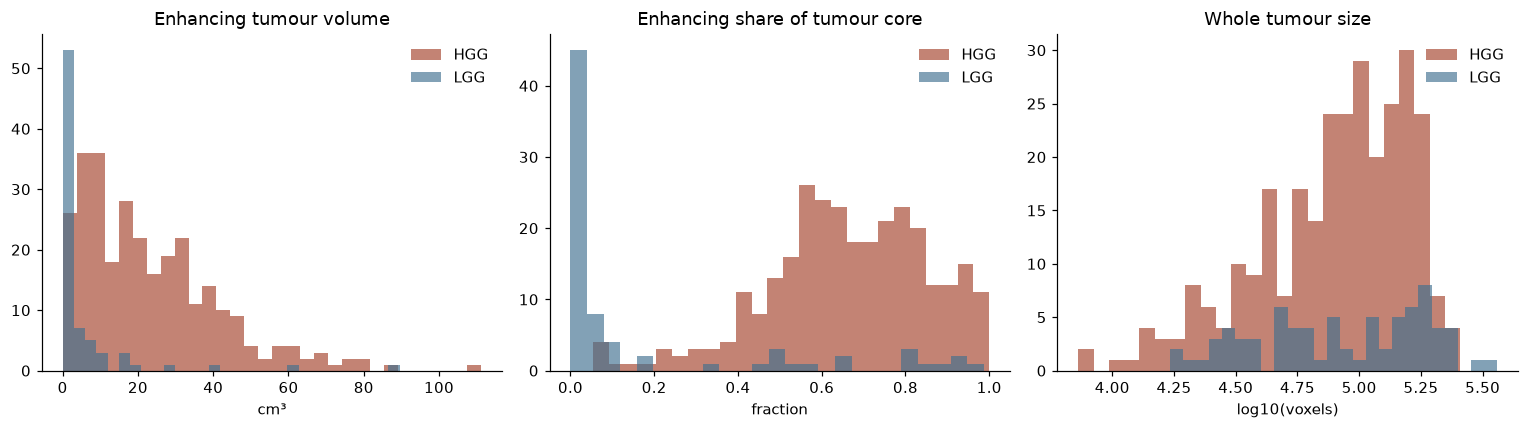

Tumours without an enhancing part: {'HGG': 0, 'LGG': 27}


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
palette = {'HGG': '#a3412a', 'LGG': '#3f6f8f'}

for grade in ('HGG', 'LGG'):
    subset = data[data['grade'] == grade]
    axes[0].hist(subset['ET_voxels'] / 1000, bins=30, alpha=.65, color=palette[grade], label=grade)
    axes[1].hist(subset['vol_ET_fraction_of_TC'], bins=25, alpha=.65, color=palette[grade], label=grade)
    axes[2].hist(subset['vol_log_WT'], bins=25, alpha=.65, color=palette[grade], label=grade)

axes[0].set(title='Enhancing tumour volume', xlabel='cm³')
axes[1].set(title='Enhancing share of tumour core', xlabel='fraction')
axes[2].set(title='Whole tumour size', xlabel='log10(voxels)')
for ax in axes:
    ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(FIGURES / 'grade_differences.png', bbox_inches='tight')
plt.show()

no_et = data.groupby('grade')['ET_present'].apply(lambda s: (s == 0).sum())
print('Tumours without an enhancing part:', no_et.to_dict())

Contrast enhancement is the classic radiological sign of a high-grade glioma: **every HGG in the dataset enhances,
while 27 of 76 LGG do not enhance at all**, and in the others the enhancing part is a much smaller share of the core.
Whole-tumour size barely differs.

## 3. Standard evaluation: repeated cross-validation

Four feature groups × three models, 5-fold stratified CV repeated 3 times (15 folds). Imputation, scaling and the
LASSO's feature selection are all fit inside each training fold, so nothing leaks from the test folds.
LGG is the positive class. Metrics: ROC AUC, balanced accuracy and average precision for LGG
(plain accuracy is misleading: predicting HGG for everyone is already 79% accurate).

In [5]:
models = M.make_models()
cv_rows = []
for group, columns in groups.items():
    for name, model in models.items():
        folds = M.cross_validate(model, data[columns], y)
        cv_rows.append({'features': group, 'model': name,
                        **{f'{k}': folds[k].mean() for k in folds},
                        'ROC AUC sd': folds['ROC AUC'].std()})
baseline_folds = M.cross_validate(M.baseline(), data[groups['volumes (6)']], y)
cv_results = pd.DataFrame(cv_rows)
cv_results.loc[len(cv_results)] = {'features': '—', 'model': 'baseline (class prior)',
                                   **baseline_folds.mean().to_dict(), 'ROC AUC sd': 0.0}
cv_results.to_csv(ROOT / 'results' / 'cv_results.csv', index=False)
cv_results.round(3)

,features,model,ROC AUC,balanced accuracy,average precision (LGG),ROC AUC sd
0,volumes (6),LASSO logistic regression,0.903,0.852,0.870,0.052
1,volumes (6),random forest,0.908,0.860,0.867,0.041
2,volumes (6),gradient boosting,0.886,0.843,0.833,0.054
3,shape,LASSO logistic regression,0.952,0.895,0.915,0.033
4,shape,random forest,0.942,0.869,0.900,0.031
5,shape,gradient boosting,0.939,0.873,0.900,0.029
6,intensity + texture,LASSO logistic regression,0.924,0.871,0.836,0.048
7,intensity + texture,random forest,0.948,0.862,0.879,0.030
8,intensity + texture,gradient boosting,0.940,0.864,0.875,0.040
9,all radiomics,LASSO logistic regression,0.953,0.890,0.908,0.033


On this evaluation everything looks excellent (AUC ≈ 0.95), and the 592 intensity and texture features seem to
do about as well as the 48 shape features. The next two checks show why the second impression is misleading.

## 4. Does the model learn the tumour or the scanner?

### 4a. Mixed-source test set
Train on every source where grade and source coincide, then test on the **39 patients from the 2013 and TMC
subsets**, where both grades come from the same source. Here the scanner cannot reveal the grade.

In [6]:
mixed = data['source'].isin(['2013', 'TMC'])
print('test set:', data.loc[mixed, 'grade'].value_counts().to_dict())

mixed_rows, mixed_probabilities = [], {}
for group, columns in groups.items():
    for name, model in models.items():
        fitted = clone(model).fit(data.loc[~mixed, columns], y[~mixed])
        probability = fitted.predict_proba(data.loc[mixed, columns])[:, 1]
        auc, low, high = M.bootstrap_auc(y[mixed], probability)
        mixed_rows.append({'features': group, 'model': name, 'ROC AUC': auc, '95% CI low': low, '95% CI high': high})
        mixed_probabilities[(group, name)] = probability
mixed_results = pd.DataFrame(mixed_rows)
mixed_results.to_csv(ROOT / 'results' / 'mixed_source_results.csv', index=False)
mixed_results.round(3)

test set: {'HGG': 28, 'LGG': 11}


,features,model,ROC AUC,95% CI low,95% CI high
0,volumes (6),LASSO logistic regression,0.886,0.672,1.000
1,volumes (6),random forest,0.880,0.670,1.000
2,volumes (6),gradient boosting,0.916,0.733,1.000
3,shape,LASSO logistic regression,0.932,0.766,1.000
4,shape,random forest,0.916,0.743,1.000
5,shape,gradient boosting,0.909,0.698,1.000
6,intensity + texture,LASSO logistic regression,0.877,0.654,1.000
7,intensity + texture,random forest,0.860,0.648,1.000
8,intensity + texture,gradient boosting,0.867,0.644,0.997
9,all radiomics,LASSO logistic regression,0.912,0.700,1.000


### 4b. Can the features recognise the source?
Among **HGG patients only** (so grade cannot help), predict whether a scan comes from CBICA or TCIA.
An AUC near 0.5 would mean the features carry no scanner information.

In [7]:
hgg = data[(data['grade'] == 'HGG') & data['source'].isin(['CBICA', 'TCIA'])]
is_cbica = (hgg['source'] == 'CBICA').astype(int)
print('HGG cases:', is_cbica.value_counts().rename({1: 'CBICA', 0: 'TCIA'}).to_dict())

source_rows = []
for group, columns in groups.items():
    folds = cross_val_score(clone(models['LASSO logistic regression']), hgg[columns], is_cbica, scoring='roc_auc',
                            cv=StratifiedKFold(5, shuffle=True, random_state=M.RANDOM_STATE))
    source_rows.append({'features': group, 'source-prediction AUC': folds.mean(), 'sd': folds.std()})
source_results = pd.DataFrame(source_rows)
source_results.to_csv(ROOT / 'results' / 'source_fingerprint.csv', index=False)
source_results.round(3)

HGG cases: {'CBICA': 129, 'TCIA': 102}


,features,source-prediction AUC,sd
0,volumes (6),0.732,0.050
1,shape,0.910,0.043
2,intensity + texture,0.990,0.014
3,all radiomics,0.990,0.014


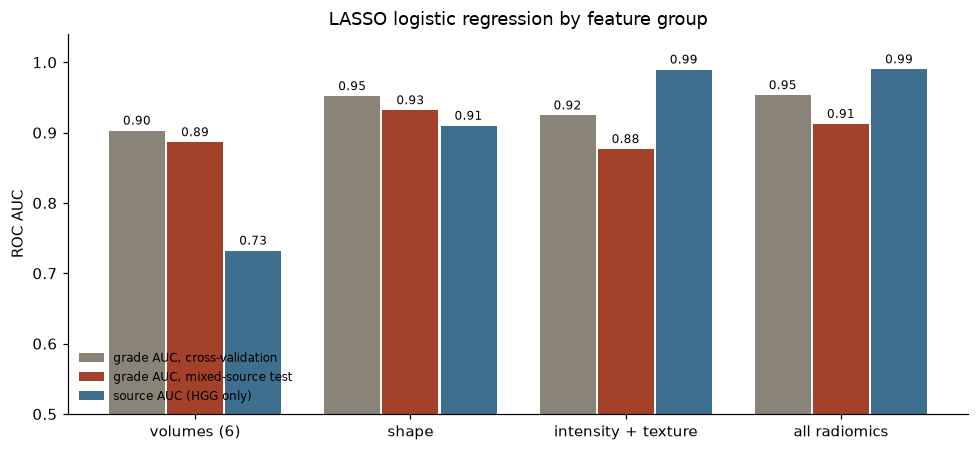

,"grade AUC, cross-validation","grade AUC, mixed-source test",source AUC (HGG only)
features,,,
volumes (6),0.903,0.886,0.732
shape,0.952,0.932,0.910
intensity + texture,0.924,0.877,0.990
all radiomics,0.953,0.912,0.990


In [8]:
lasso = 'LASSO logistic regression'
summary = pd.DataFrame({
    'grade AUC, cross-validation': cv_results[cv_results['model'] == lasso].set_index('features')['ROC AUC'],
    'grade AUC, mixed-source test': mixed_results[mixed_results['model'] == lasso].set_index('features')['ROC AUC'],
    'source AUC (HGG only)': source_results.set_index('features')['source-prediction AUC'],
})

fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(summary))
for offset, (column, color) in zip((-0.27, 0, 0.27), zip(summary.columns, ('#8a8377', '#a3412a', '#3f6f8f'))):
    bars = ax.bar(x + offset, summary[column], width=0.26, color=color, label=column)
    ax.bar_label(bars, fmt='%.2f', fontsize=8, padding=2)
ax.set_xticks(x, summary.index)
ax.set_ylim(0.5, 1.04)
ax.set_ylabel('ROC AUC')
ax.set_title('LASSO logistic regression by feature group')
ax.legend(frameon=False, fontsize=8, loc='lower left')
plt.tight_layout()
plt.savefig(FIGURES / 'feature_groups_summary.png', bbox_inches='tight')
plt.show()
summary.round(3)

* **Intensity and texture features identify the source almost perfectly** (AUC ≈ 0.99 among HGG patients), even
  after z-score normalisation of every sequence. Part of their cross-validation score is therefore the scanner,
  and on the mixed-source patients they drop below the shape features.
* **Shape features** are far less source-specific and generalise best. Some source signal remains even in shape
  (AUC ≈ 0.91), most likely because tumour masks were drawn with different protocols at different sites.
* The mixed-source test has only 39 patients (11 LGG): the confidence intervals are wide, so the ranking between
  groups there is indicative, not conclusive.

**Selected model:** LASSO logistic regression on the shape features — the best or joint-best score in both
evaluations, the least scanner-dependent feature set, and a model small enough to interpret.

## 5. The selected model

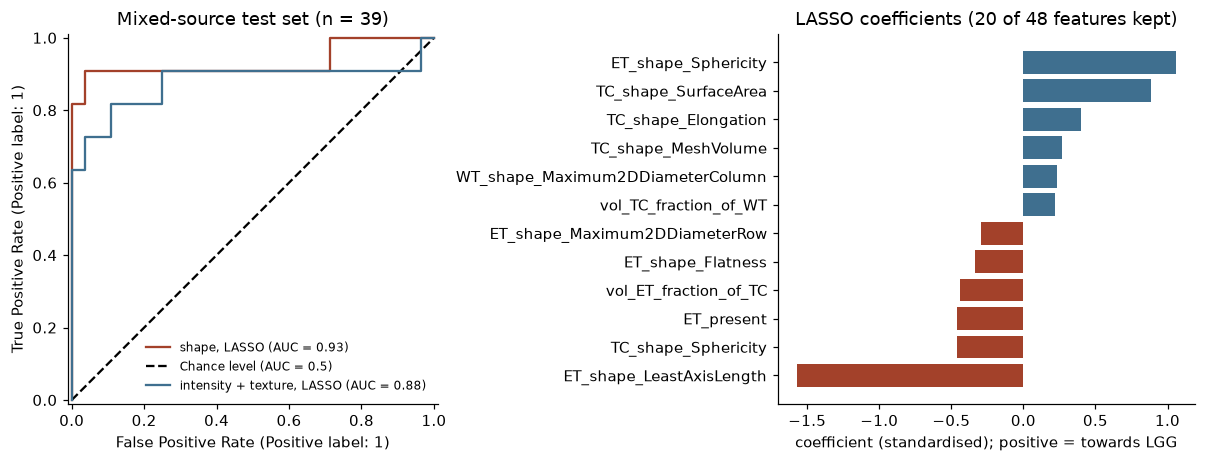

Selected C: 0.3


In [9]:
final_features = groups['shape']
final_name = ('shape', lasso)
probability = mixed_probabilities[final_name]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
RocCurveDisplay.from_predictions(y[mixed], probability, ax=axes[0], name='shape, LASSO',
                                 curve_kwargs={'color': '#a3412a'}, plot_chance_level=True)
RocCurveDisplay.from_predictions(y[mixed], mixed_probabilities[('intensity + texture', lasso)], ax=axes[0],
                                 name='intensity + texture, LASSO', curve_kwargs={'color': '#3f6f8f'})
axes[0].set_title('Mixed-source test set (n = 39)')
axes[0].legend(loc='lower right', fontsize=8, frameon=False)

final = clone(models[lasso]).fit(data[final_features], y)
estimator = final.best_estimator_
kept = estimator.named_steps['variance'].get_feature_names_out(final_features)
coefficients = pd.Series(estimator.named_steps['model'].coef_[0], index=kept)
coefficients = coefficients[coefficients != 0].sort_values()
top = pd.concat([coefficients.head(6), coefficients.tail(6)]).drop_duplicates()
axes[1].barh(top.index, top.values, color=np.where(top.values > 0, '#3f6f8f', '#a3412a'))
axes[1].set_title(f'LASSO coefficients ({len(coefficients)} of {len(kept)} features kept)')
axes[1].set_xlabel('coefficient (standardised); positive = towards LGG')
plt.tight_layout()
plt.savefig(FIGURES / 'final_model.png', bbox_inches='tight')
plt.show()
print('Selected C:', final.best_params_['model__C'])

The selected model keeps 20 of the 48 shape features. The strongest pushes towards **HGG** are a thicker enhancing
region (larger smallest axis), the presence and share of enhancement, and a more spherical tumour core. Shape features are strongly
correlated with each other and the LASSO keeps only one of each correlated group, so individual coefficients
should be read as "this kind of shape information matters", not as independent effects.

## Conclusion

1. **Enhancement decides most cases.** Every HGG in BraTS 2020 has an enhancing part; 27 of 76 LGG have none.
   Six simple volume features already reach ROC AUC ≈ 0.90.
2. **Standard cross-validation says everything works** (AUC ≈ 0.95 for shape, texture and all features), but
   **the data source almost determines the grade** in this dataset.
3. **Intensity and texture radiomics carry a strong scanner fingerprint**: they tell CBICA from TCIA scans with
   AUC 0.99 among HGG patients alone. On the 39 patients whose source contains both grades, texture-based models
   drop to AUC 0.86–0.88.
4. **Shape features generalise best**: LASSO logistic regression on 48 shape features scores AUC 0.95 in
   cross-validation and 0.93 (95% CI 0.77–1.00) on the mixed-source patients.

**Limitations.** The mixed-source test set is small (39 patients, 11 LGG), so its confidence intervals are wide.
Features come from expert masks; a real pipeline would use automatic segmentation, which adds error. Shape features
still carry some source information (AUC 0.91), probably from site-specific annotation, so even the shape result is
likely somewhat optimistic. BraTS labels only LGG vs HGG; WHO 2021 grading also depends on molecular markers
(IDH, 1p/19q) that are not available here.